In [2]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (383 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [4]:
routes = pd.read_csv(
    "data/processed/nuego_train_241_ac_sleeper.csv"
)

competitor = pd.read_csv(
    "data/processed/competitor_preprocessed3.csv"
)

print("NueGo shape:", routes.shape)
print("Competitor shape:", competitor.shape)

display(routes.head())
display(competitor.head())

NueGo shape: (240, 12)
Competitor shape: (1225, 24)


,Route ID,Available Seats,Total Seats,Distance (km),holiday_score,Departure Month,Departure Weekday,Departure Hour,Duration (hours),Fare on Sale (INR),AC,Sleeper
0,R001,25,40,267,0.5,1,2,8,5.25,385,0,0
1,R002,34,40,256,1.0,1,3,17,5.75,520,1,1
2,R003,8,40,345,0.5,1,4,20,9.00,890,1,0
3,R004,28,40,270,0.5,1,2,21,5.00,450,0,1
4,R005,23,40,239,1.0,1,3,22,5.25,420,0,1


,Route ID,Base Fare (INR),Fare (INR),Holiday,Duration (hours),departure_month,departure_weekday,availability_ratio,days_to_departure,AC,...,Competitor Name_HRTC,Competitor Name_Haryana Roadways,Competitor Name_IntrCity SmartBus,Competitor Name_LEAFYBUS,Competitor Name_Laxmi Holidays,Competitor Name_RSK Holidays,Competitor Name_RSRTC,Competitor Name_UPSRTC,Competitor Name_UTC,Competitor Name_zingbus
0,R001,0.013793,240,0.5,0.0,0.0,0.333333,0.75000,0.162162,0,...,1,0,0,0,0,0,0,0,0,0
1,R001,0.096552,305,1.0,0.0,0.0,0.500000,0.87500,0.162162,1,...,0,0,0,0,0,0,0,0,0,0
2,R001,0.151724,355,0.5,0.0,0.0,0.666667,0.75000,0.162162,1,...,0,0,0,0,0,0,0,0,0,1
3,R001,0.220690,360,0.0,0.0,0.0,0.833333,0.62500,0.162162,1,...,0,0,0,0,1,0,0,0,0,0
4,R001,0.131034,295,0.0,0.0,0.0,0.166667,0.65625,0.162162,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
print("NueGo missing values:")
print(routes.isnull().sum())

print("\nCompetitor missing values:")
print(competitor.isnull().sum())

print("\nDuplicate rows:")
print("NueGo:", routes.duplicated().sum())
print("Competitor:", competitor.duplicated().sum())

print("\nNueGo AC values:", routes["AC"].unique())
print("NueGo Sleeper values:", routes["Sleeper"].unique())

NueGo missing values:
Route ID              0
Available Seats       0
Total Seats           0
Distance (km)         0
holiday_score         0
Departure Month       0
Departure Weekday     0
Departure Hour        0
Duration (hours)      0
Fare on Sale (INR)    0
AC                    0
Sleeper               0
dtype: int64

Competitor missing values:
Route ID                             0
Base Fare (INR)                      0
Fare (INR)                           0
Holiday                              0
Duration (hours)                     0
departure_month                      0
departure_weekday                    0
availability_ratio                   0
days_to_departure                    0
AC                                   0
Sleeper                              0
Competitor Name_Bedi Travels         0
Competitor Name_CTU                  0
Competitor Name_FlixBus              0
Competitor Name_HRTC                 0
Competitor Name_Haryana Roadways     0
Competitor Name_IntrCity 

In [8]:
# 1. Define column lists and mappings with correct string quotes
fare_cols = ["competitor_min_fare", "competitor_median_fare", "competitor_avg_fare"]

# 2. Level 1: Group by Route and Coach specifications
competitor_summary = (
    competitor.groupby(["Route ID", "AC", "Sleeper"])["Fare (INR)"]
    .agg(
        competitor_min_fare="min",
        competitor_median_fare="median",
        competitor_avg_fare="mean",
    )
    .reset_index()
)

combined = routes.merge(
    competitor_summary, on=["Route ID", "AC", "Sleeper"], how="left"
)

# 3. Level 2: Group by Route ID only for the fallback stats
route_summary = (
    competitor.groupby("Route ID")["Fare (INR)"]
    .agg(route_min="min", route_median="median", route_avg="mean")
    .reset_index()
)

combined = combined.merge(route_summary, on="Route ID", how="left")

# 4. Apply the fallback replacement mapping strings to strings
fallback = {
    "competitor_min_fare": "route_min",
    "competitor_median_fare": "route_median",
    "competitor_avg_fare": "route_avg",
}

for col, fallback_col in fallback.items():
    combined[col] = combined[col].fillna(combined[fallback_col])

# 5. Clean up temporary fallback columns
combined = combined.drop(columns=["route_min", "route_median", "route_avg"])

# 6. Diagnostics
print("Combined shape:", combined.shape)
print("Missing competitor fares:")
print(combined[fare_cols].isnull().sum())


Combined shape: (240, 15)
Missing competitor fares:
competitor_min_fare       0
competitor_median_fare    0
competitor_avg_fare       0
dtype: int64


In [9]:
numeric_features = [
    "Available Seats",
    "Total Seats",
    "Distance (km)",
    "holiday_score",
    "Departure Month",
    "Departure Weekday",
    "Departure Hour",
    "Duration (hours)",
    *fare_cols
]

categorical_features = ["Route ID", "AC", "Sleeper"]

X = combined[numeric_features + categorical_features]
y = combined["Fare on Sale (INR)"]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
], remainder="passthrough")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    preprocessor,
    DecisionTreeRegressor(
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    )
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R²:", round(r2_score(y_test, predictions), 3))

MAE: 70.87
RMSE: 92.11
R²: 0.772


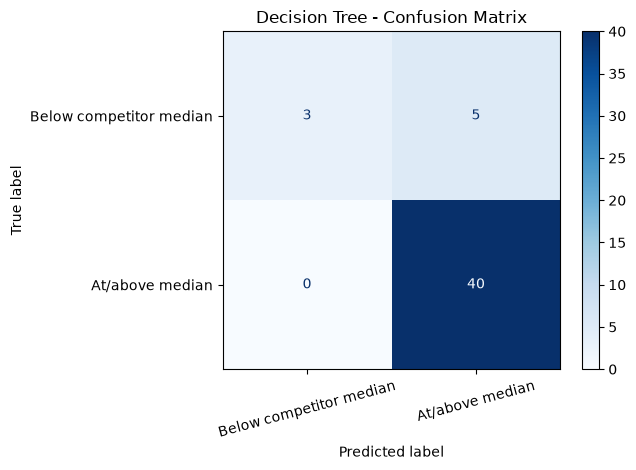

Accuracy: 0.896
Precision: 1.0
Recall: 0.375
F1 Score: 0.545


In [14]:
competitor_fare = X_test["competitor_median_fare"].to_numpy()

actual = y_test.to_numpy() < competitor_fare
predicted = predictions < competitor_fare

cm = confusion_matrix(actual, predicted, labels=[True, False])

display_labels = ["Below competitor median", "At/above median"]

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
).plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Confusion Matrix")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Accuracy:", round(accuracy_score(actual, predicted), 3))
print("Precision:", round(precision_score(actual, predicted, zero_division=0), 3))
print("Recall:", round(recall_score(actual, predicted, zero_division=0), 3))
print("F1 Score:", round(f1_score(actual, predicted, zero_division=0), 3))

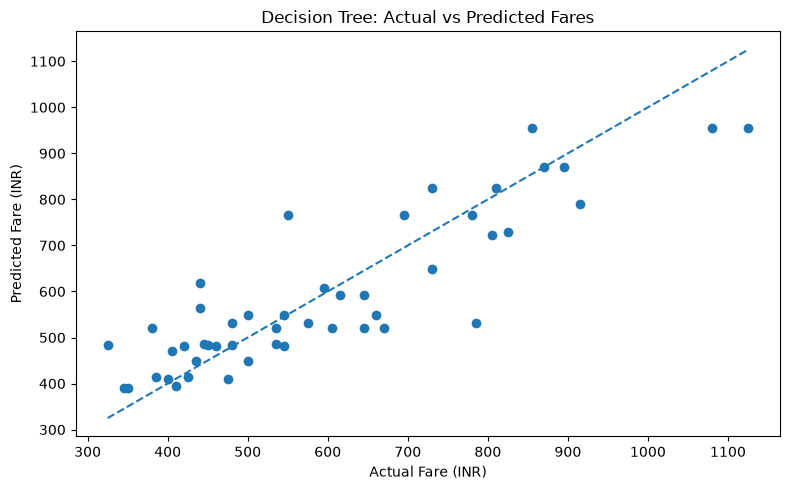

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

min_fare = min(y_test.min(), predictions.min())
max_fare = max(y_test.max(), predictions.max())

plt.plot(
    [min_fare, max_fare],
    [min_fare, max_fare],
    linestyle="--"
)

plt.xlabel("Actual Fare (INR)")
plt.ylabel("Predicted Fare (INR)")
plt.title("Decision Tree: Actual vs Predicted Fares")
plt.tight_layout()
plt.show()

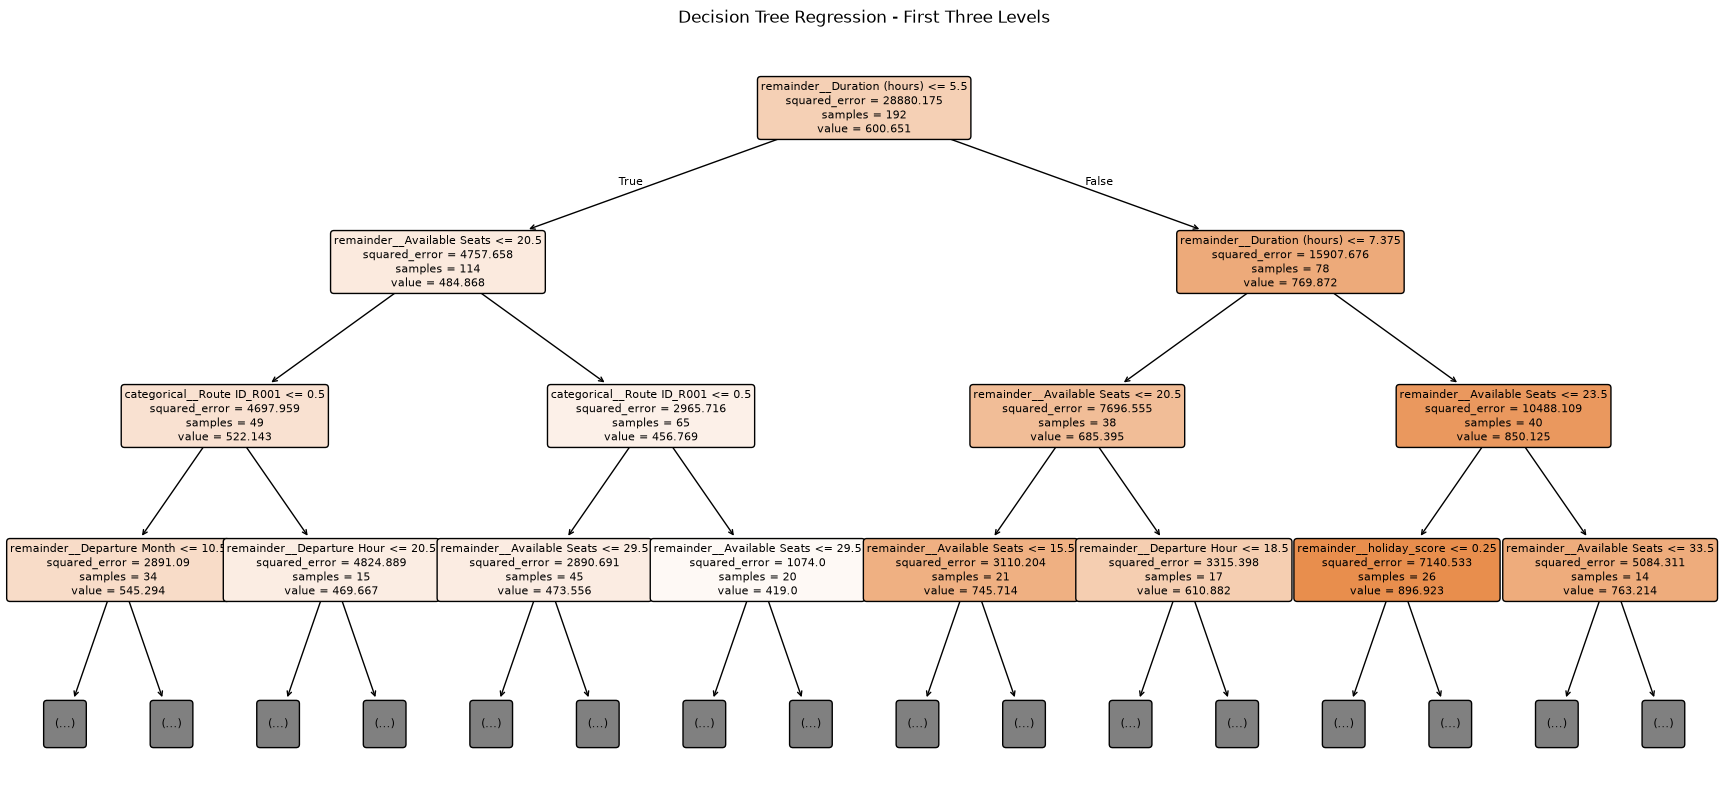

In [12]:
tree_model = model.named_steps["decisiontreeregressor"]
feature_names = model.named_steps["columntransformer"].get_feature_names_out()

plt.figure(figsize=(22, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Regression - First Three Levels")
plt.show()

In [13]:
results = X_test.copy()

results["Actual Fare (INR)"] = y_test.to_numpy()
results["Predicted Fare (INR)"] = np.round(predictions, 2)
results["Fare Difference (INR)"] = np.round(
    predictions - y_test.to_numpy(), 2
)

results.to_csv(
    "data/processed/nuego_decision_tree_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!
